# Cross-validated peer assessment: interactive simulation

Companion notebook to *Under What Conditions Does a Cross-Validated Peer Assessment Mechanism Induce Truthful Reporting and Eliminate Free-Riding in Student Group Work?* (John Headley, EC3009 BSc Economics Project, City, University of London, May 2026).

It reuses the numerical example of Section 4.2 of the paper: a group of four students (Alice, Bob, Chloé, David) with true efforts $(4, 3, 4, 2)$ and a common group grade $G = 72$. David is a free rider; Alice inflates her rating of Bob by $+2$ and Bob inflates his rating of Alice by $+1$.

The mechanism itself lives in [`paf_mechanism.py`](../paf_mechanism.py); this notebook only calls it and draws the figures:

1. a bar chart of grades under the standard PAF and the cross-validated PAF,
2. a line chart of each student's grade as a function of the penalty parameter $\alpha$,
3. a heatmap of the credibility weights $w_{ij}$.

The interactive controls (slider for $\alpha$, numeric input for $G$) need a live kernel: run the notebook locally with `jupyter notebook`.

In [ ]:
import sys
sys.path.insert(0, "..")  # the mechanism module sits at the repository root

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import ipywidgets as widgets
from IPython.display import display

import paf_mechanism as paf

STUDENTS = list(paf.STUDENTS)
HONEST = paf.EXAMPLE_HONEST
COLLUSION = paf.EXAMPLE_COLLUSION
print("Honest ratings (rows = rater, columns = rated):\n", HONEST)
print("\nRatings with collusion:\n", COLLUSION)

Honest ratings (rows = rater, columns = rated):
 [[nan  3.  4.  2.]
 [ 4. nan  4.  2.]
 [ 4.  3. nan  2.]
 [ 4.  3.  4. nan]]

Ratings with collusion:
 [[nan  5.  4.  2.]
 [ 5. nan  4.  2.]
 [ 4.  3. nan  2.]
 [ 4.  3.  4. nan]]


## Plotting helpers

Colours follow one fixed categorical order (blue, orange, aqua, yellow) so a student keeps the same colour in every figure; the heatmap uses a single blue ramp because the weights are magnitudes in $[0, 1]$.

In [ ]:
# ---- palette -------------------------------------------------------------
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # one colour per student / series
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SURFACE = "#fcfcfb"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
ALPHA_GRID = np.round(np.arange(0.0, 1.0, 0.01), 2)  # alpha = 1 is excluded: see the paper, Section 4.2
ALPHA_STAR_ALICE = 0.96  # dotted reference line of Figure 5 of the paper


def _style(ax):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=9)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def plot_grade_bars(alpha=0.5, G=72.0, ax=None):
    """Figure (a): standard PAF vs cross-validated PAF under collusion."""
    std = paf.standard_grades(COLLUSION, G)
    cv = paf.cross_validated_grades(COLLUSION, G, alpha)
    if ax is None:
        _, ax = plt.subplots(figsize=(7.5, 4.2), facecolor=SURFACE)
    x = np.arange(len(STUDENTS))
    width = 0.34
    b1 = ax.bar(x - width / 2 - 0.01, std, width, color=SERIES[0], label="Standard PAF")
    b2 = ax.bar(x + width / 2 + 0.01, cv, width, color=SERIES[1], label=f"Cross-validated PAF, α = {alpha:.2f}")
    ax.axhline(G, color=MUTED, linestyle="--", linewidth=1.2, label=f"Group grade G = {G:g}")
    for bars in (b1, b2):
        for bar in bars:
            ax.annotate(f"{bar.get_height():.1f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                        fontsize=8.5, color=INK2)
    _style(ax)
    ax.set_xticks(x, STUDENTS)
    ax.set_ylabel("Individual grade", color=INK2)
    ax.set_ylim(0, max(std.max(), cv.max()) * 1.28)
    ax.set_title("Individual grades under collusion: standard vs cross-validated PAF", fontsize=11, color=INK, loc="left")
    ax.legend(frameon=False, fontsize=9, loc="upper center", ncol=3, columnspacing=1.4)
    return ax


def plot_grades_vs_alpha(alpha=0.5, G=72.0, ax=None):
    """Figure (b): each student's grade as a function of alpha (collusion scenario)."""
    grades = np.array([paf.cross_validated_grades(COLLUSION, G, a) for a in ALPHA_GRID])
    if ax is None:
        _, ax = plt.subplots(figsize=(7.5, 4.2), facecolor=SURFACE)
    for k, name in enumerate(STUDENTS):
        ax.plot(ALPHA_GRID, grades[:, k], color=SERIES[k], linewidth=2, label=name)
    # direct labels at the right end, pushed apart when two lines end at the same height
    ends = grades[-1].copy()
    label_y = ends.copy()
    order = np.argsort(ends)
    for a, b in zip(order[:-1], order[1:]):
        if label_y[b] - label_y[a] < 2.2:
            label_y[b] = label_y[a] + 2.2
    for k, name in enumerate(STUDENTS):
        ax.annotate(name, (ALPHA_GRID[-1], ends[k]), xytext=(ALPHA_GRID[-1] + 0.02, label_y[k]),
                    textcoords="data", va="center", fontsize=9, color=INK2,
                    arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8, shrinkA=0, shrinkB=2)
                    if abs(label_y[k] - ends[k]) > 0.3 else None)
    ax.axvline(alpha, color=MUTED, linestyle="--", linewidth=1.2, label=f"current α = {alpha:.2f}")
    ax.axvline(ALPHA_STAR_ALICE, color=INK2, linestyle=":", linewidth=1.2, label=f"α* (Alice) ≈ {ALPHA_STAR_ALICE:.2f}")
    _style(ax)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel("Penalty parameter α", color=INK2)
    ax.set_ylabel("Individual grade", color=INK2)
    ax.set_title("Individual grades as a function of α (collusion scenario)", fontsize=11, color=INK, loc="left")
    ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(0.02, 0.36))
    return ax


def plot_weight_heatmap(alpha=0.5, ax=None):
    """Figure (c): credibility weights w_ij. Rows: raters. Columns: rated."""
    w = paf.credibility_weights(COLLUSION, alpha)
    if ax is None:
        _, ax = plt.subplots(figsize=(5.6, 4.6), facecolor=SURFACE)
    masked = np.ma.masked_invalid(w)
    cmap = BLUE_RAMP.copy()
    cmap.set_bad("#f0efec")
    im = ax.imshow(masked, cmap=cmap, vmin=0, vmax=1)
    n = len(STUDENTS)
    for i in range(n):
        for j in range(n):
            if i == j:
                ax.text(j, i, "—", ha="center", va="center", color=MUTED, fontsize=10)
            else:
                ax.text(j, i, f"{w[i, j]:.2f}", ha="center", va="center", fontsize=10,
                        color="#f0efec" if w[i, j] > 0.55 else INK)
    ax.set_xticks(range(n), STUDENTS)
    ax.set_yticks(range(n), STUDENTS)
    ax.set_xlabel("Rated student j", color=INK2)
    ax.set_ylabel("Rater i", color=INK2)
    ax.tick_params(colors=INK2, labelsize=9, length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"Credibility weights $w_{{ij}}$ at α = {alpha:.2f}", fontsize=11, color=INK, loc="left")
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.ax.tick_params(colors=INK2, labelsize=8)
    cb.outline.set_visible(False)
    return ax


def summary_table(alpha=0.5, G=72.0):
    """Numerical comparison of grades with budget-balance and collusion-backfire checks."""
    honest = paf.standard_grades(HONEST, G)
    std = paf.standard_grades(COLLUSION, G)
    cv = paf.cross_validated_grades(COLLUSION, G, alpha)
    print(f"{'Student':<8}{'PAF honest':>12}{'PAF collusion':>15}{'Cross-val α=' + format(alpha, '.2f'):>18}{'Δ vs honest':>13}")
    for k, name in enumerate(STUDENTS):
        print(f"{name:<8}{honest[k]:>12.1f}{std[k]:>15.1f}{cv[k]:>18.1f}{cv[k] - honest[k]:>+13.1f}")
    n = len(STUDENTS)
    print(f"{'Sum':<8}{honest.sum():>12.1f}{std.sum():>15.1f}{cv.sum():>18.1f}   (budget: n × G = {n * G:g})")
    gain_A, gain_B = cv[0] - honest[0], cv[1] - honest[1]
    print(f"\nCoalition (Alice + Bob) joint gain vs honest baseline: {gain_A + gain_B:+.1f} points "
          f"(Alice {gain_A:+.1f}, Bob {gain_B:+.1f})")
    if gain_B < 0 or gain_A < 0:
        print("Collusion backfires on at least one member of the coalition.")

## Interactive controls

Move the slider for $\alpha \in [0, 1]$ and change the group grade $G$. At $\alpha = 0$ the cross-validated mechanism is the standard PAF. The slider goes up to $\alpha = 1$ as in the paper; note that at $\alpha = 1$ exactly the corrupted consensus discounts Chloé's and David's honest ratings of Bob to zero and the mechanism falls back to the plain mean of Bob's ratings (Section 4.2 of the paper explains why $\alpha = 0.99$ is used instead of the limit).

In [ ]:
def simulate(alpha=0.5, G=72.0):
    summary_table(alpha, G)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), facecolor=SURFACE)
    plot_grade_bars(alpha, G, ax=axes[0])
    plot_grades_vs_alpha(alpha, G, ax=axes[1])
    plt.tight_layout()
    plt.show()
    plot_weight_heatmap(alpha)
    plt.tight_layout()
    plt.show()


widgets.interact(
    simulate,
    alpha=widgets.FloatSlider(value=0.5, min=0.0, max=1.0, step=0.01, description="α", readout_format=".2f"),
    G=widgets.FloatText(value=72.0, description="Group grade G"),
);

## Static figures at $\alpha = 0.5$, $G = 72$

These are the figures embedded in the README; they are also saved to `../figures/`.

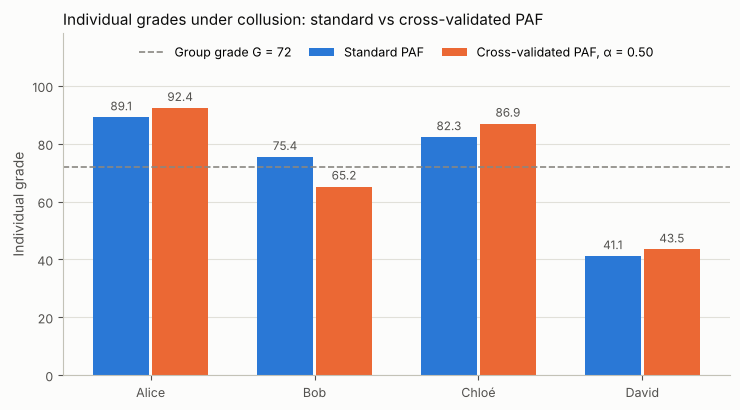

In [ ]:
ax = plot_grade_bars(0.5, 72.0)
plt.tight_layout(); plt.savefig("../figures/fig1_grades_standard_vs_crossvalidated.png", dpi=160, facecolor=SURFACE)
plt.show()

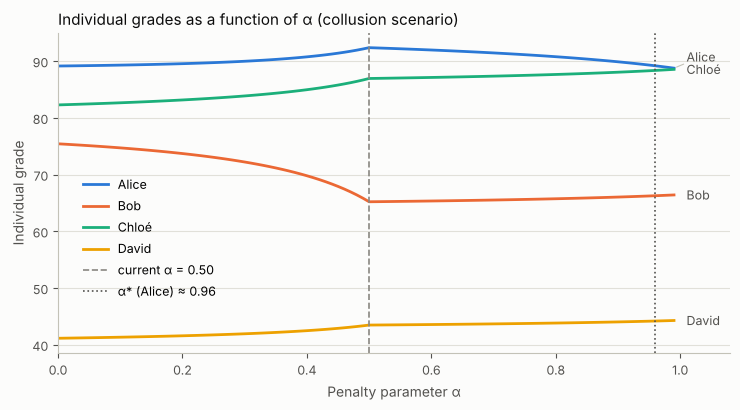

In [ ]:
ax = plot_grades_vs_alpha(0.5, 72.0)
plt.tight_layout(); plt.savefig("../figures/fig2_grades_vs_alpha.png", dpi=160, facecolor=SURFACE)
plt.show()

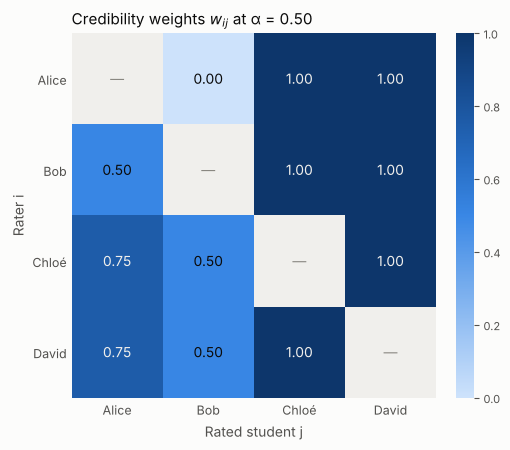

In [ ]:
ax = plot_weight_heatmap(0.5)
plt.tight_layout(); plt.savefig("../figures/fig3_credibility_weights.png", dpi=160, facecolor=SURFACE)
plt.show()

## Numerical comparison at $\alpha = 0.5$

Budget balance holds in every column ($\sum_j G_j = 4 \times 72 = 288$), and the coalition is internally unstable: Alice gains while Bob loses.

In [ ]:
summary_table(0.5, 72.0)
print()
summary_table(0.99, 72.0)

Student   PAF honest  PAF collusion  Cross-val α=0.50  Δ vs honest
Alice           88.6           89.1              92.4         +3.8
Bob             66.5           75.4              65.2         -1.3
Chloé           88.6           82.3              86.9         -1.7
David           44.3           41.1              43.5         -0.8
Sum            288.0          288.0             288.0   (budget: n × G = 288)

Coalition (Alice + Bob) joint gain vs honest baseline: +2.5 points (Alice +3.8, Bob -1.3)
Collusion backfires on at least one member of the coalition.

Student   PAF honest  PAF collusion  Cross-val α=0.99  Δ vs honest
Alice           88.6           89.1              88.8         +0.2
Bob             66.5           75.4              66.4         -0.1
Chloé           88.6           82.3              88.5         -0.1
David           44.3           41.1              44.3         -0.0
Sum            288.0          288.0             288.0   (budget: n × G = 288)

Coalition (Alice + B